In [124]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [125]:
FINAL_CONFIGS = [
    "primary_final",
    "supplementary_randomized_r10",
    "supplementary_evo_r10",
    "supplementary_evo_r12",
]

*RQ1*: Do we find violations with randomized Byzzfuzz?

In [126]:
df = pd.read_csv("./final-thesis-bug4-as-bug3/data/randomized_seed_violation_plot_data.csv")
df

,benchmark,seed,valid_executions,agreement_violations,liveness_violations,total_violations
0,Original Aptos,42,1000,0,0,0
1,Original Aptos,100,1000,0,0,0
2,Original Aptos,2026,1000,0,0,0
3,Bug 1,42,1000,0,1,1
4,Bug 1,100,1000,0,0,0
5,Bug 1,2026,1000,0,0,0
6,Bug 2 (r=6),42,1000,11,1,12
7,Bug 2 (r=6),100,1000,7,0,7
8,Bug 2 (r=6),2026,1000,7,0,7
9,Bug 2 (r=10),42,160,5,0,5


<>:5: SyntaxWarning: invalid escape sequence '\c'
<>:5: SyntaxWarning: invalid escape sequence '\c'
/var/folders/xb/mjld121x40jcd_20cqlm78lr0000gn/T/ipykernel_1710/3681359912.py:5: SyntaxWarning: invalid escape sequence '\c'
  marker="$\circ$",


Text(0.5, 1.0, 'Randomized violations')

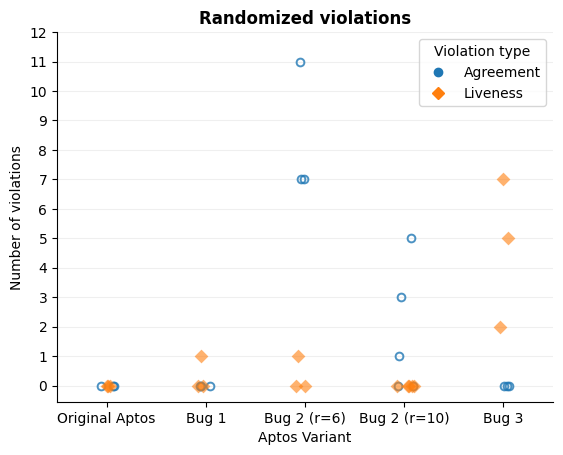

In [127]:
ax = sns.stripplot(
    data=df, 
    x="benchmark", 
    y="agreement_violations", 
    marker="$\circ$",
    size=7,
    alpha=0.8,
)
ax = sns.stripplot(
    data=df, 
    x="benchmark", 
    y="liveness_violations", 
    marker="D",
    alpha = 0.6,
    size=7,
)
ax.set(xlabel='Aptos Variant', ylabel='Number of violations', yticks=np.arange(0, 13, 1))
sns.despine(ax=ax)  # removes the top and right spines by default
plt.grid(axis="y", alpha=0.2)
colors = sns.color_palette()
ax.legend(
    handles=[
        plt.Line2D([], [], marker="o", linestyle="None",
               color=colors[0], label="Agreement"),
        plt.Line2D([], [], marker="D", linestyle="None",
               color=colors[1], label="Liveness"),
    ],
    title="Violation type",
)
plt.title("Randomized violations", fontdict={"weight":"bold"})


*RQ2*: Can we find more violations with EA as compared to randomized Byzzfuzz? We look at:
1. Violation rate between randomized and every EA strategy.
2. The cumulative violations over every fitness strategy.

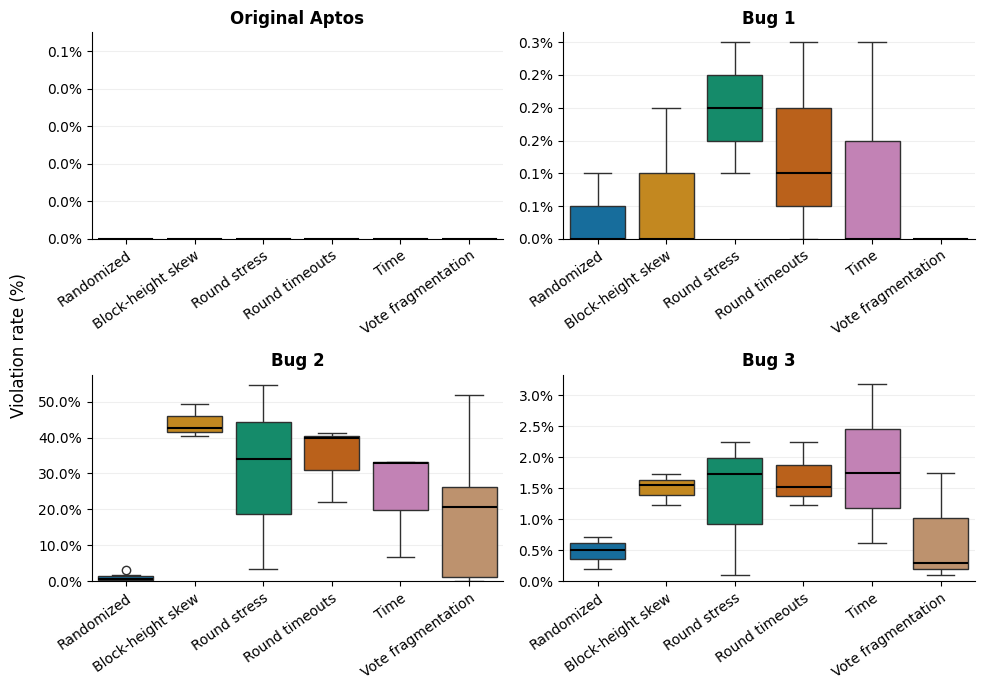

In [128]:
from matplotlib.ticker import PercentFormatter

df = pd.read_csv(
    "./final-thesis-bug4-as-bug3/data/rq2_outcome_campaign_rates_all_configs.csv"
)

df = df[df["configuration"].isin(FINAL_CONFIGS)]

df["method_label"] = df["method_label"].replace({
    "Height skew": "Block-height skew",
    "Round timeout": "Round timeouts",
    "Rand.": "Randomized",
    "Vote fragment.": "Vote fragmentation",
})

methods = df["method_label"].drop_duplicates().tolist()
benchmarks = df["benchmark_label"].drop_duplicates().tolist()
colors = dict(zip(
    methods,
    sns.color_palette("colorblind", n_colors=len(methods)),
))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, benchmark in zip(axes.flat, benchmarks):
    plot_data = df[df["benchmark_label"] == benchmark]

    sns.boxplot(
        data=plot_data,
        x="method_label",
        y="violation_rate_percent",
        hue="method_label",
        order=methods,
        hue_order=methods,
        palette=colors,
        dodge=False,
        medianprops={"color": "black", "linewidth": 1.5},
        ax=ax,
    )

    if ax.legend_:
        ax.legend_.remove()

    ax.set_title(benchmark, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelrotation=35)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=1))
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    sns.despine(ax=ax)

fig.supylabel("Violation rate (%)")
fig.tight_layout()
plt.show()

In [129]:
df = pd.read_csv("./final-thesis-bug4-as-bug3/data/rq2_all_objectives_generation_discovery_all_seeds.csv")
means = (
    df.groupby(
        ["benchmark", "benchmark_label", "method", "method_label", "x_index"],
        as_index=False,
    )["cumulative_confirmed_violations"]
    .mean()
)
means.method_label.unique()

array(['Block-height skew', 'Randomized ByzzFuzz', 'Round stress',
       'Round timeouts', 'Time', 'Vote fragmentation'], dtype=object)

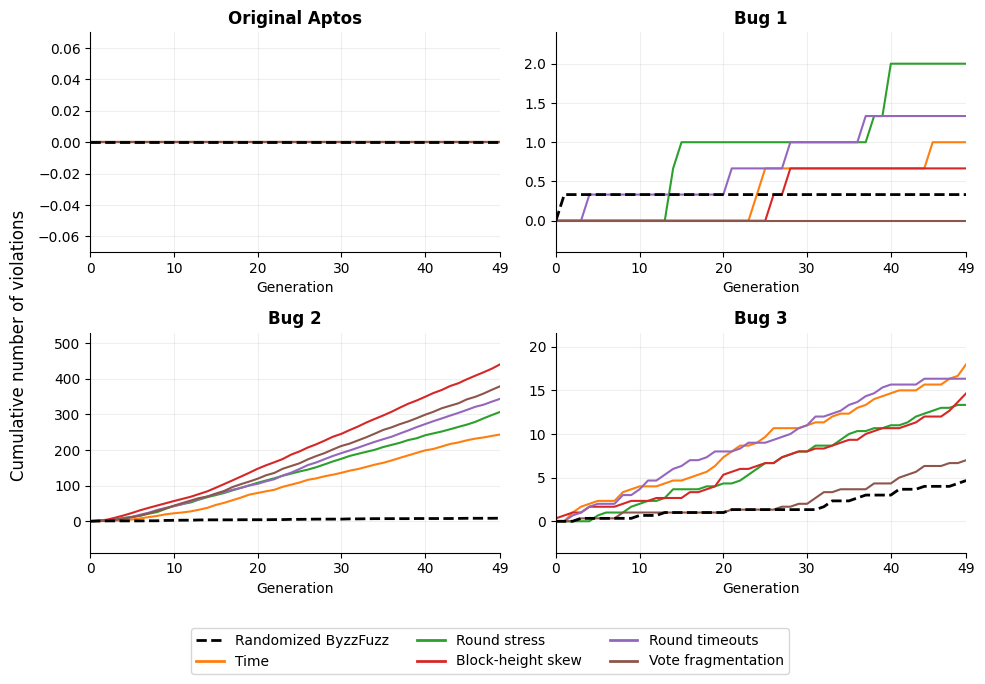

In [130]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
colors = dict(zip(df['method_label'].unique(), sns.color_palette()))
colors["Randomized ByzzFuzz"] = "black"

for ax, benchmark in zip(axes.flat, df['benchmark_label'].unique()):
    for method in df['method_label'].unique():
        series = means.loc[
            (means["benchmark_label"] == benchmark) & (means["method_label"] == method)
        ].sort_values("x_index")

        sns.lineplot(
            data=series,
            x="x_index",
            y="cumulative_confirmed_violations",
            estimator="mean",
            errorbar=None,
            sort=True,
            color=colors[method],
            linestyle="--" if method == "Randomized ByzzFuzz" else "-",
            linewidth=2 if method == "Randomized ByzzFuzz" else 1.5,
            legend=False,

            zorder=10 if method == "Randomized ByzzFuzz" else 2,
            ax=ax,
        )
        
    sns.despine(ax=ax)    
    ax.margins(y=0.2)
    ax.set_title(benchmark, fontweight="bold")
    ax.set_xlim(0, 49)
    ax.set_xticks([0, 10, 20, 30, 40, 49])
    ax.set_xlabel("Generation")
    ax.set_ylabel("")
    ax.grid(alpha=0.2)

fig.supylabel("Cumulative number of violations")
handles = [
    plt.Line2D(
        [0], [0],
        color=colors[method],
        linestyle="--" if method == "Randomized ByzzFuzz" else "-",
        linewidth=2,
        label=method,
    )
    for method in df['method_label'].unique()
]
fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    
    bbox_to_anchor=(0.5, 0.02),
)

fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

*RQ4*: About fitness values and how they grow over generations: 
-> do fitness values grow over generations?
-> are the fitness values higher than randomized Byzzfuzz?

In [131]:
df = pd.read_csv("./final-thesis-bug4-as-bug3/data/rq3_mean_fitness_ratio_by_generation.csv")
df = df[df["ratio_defined"]]
df

,benchmark,benchmark_label,method,method_label,fitness_metric,generation,x_index,x_axis_basis,mean_ea_fitness,mean_randomized_fitness,mean_ratio,mean_fitness_difference,paired_seed_count,ea_valid_executions,randomized_valid_executions,ratio_defined
0,aptos,Original Aptos,block_height_skew_fitness,Block-height skew,block_height_skew_fitness,0,0,generation / 20-execution randomized batch,5.700000,5.300000,1.075472,0.400000,3,60,60,True
1,aptos,Original Aptos,block_height_skew_fitness,Block-height skew,block_height_skew_fitness,1,1,generation / 20-execution randomized batch,5.366667,5.116667,1.048860,0.250000,3,60,60,True
2,aptos,Original Aptos,block_height_skew_fitness,Block-height skew,block_height_skew_fitness,2,2,generation / 20-execution randomized batch,5.600000,5.133333,1.090909,0.466667,3,60,60,True
3,aptos,Original Aptos,block_height_skew_fitness,Block-height skew,block_height_skew_fitness,3,3,generation / 20-execution randomized batch,5.716667,5.116667,1.117264,0.600000,3,60,60,True
4,aptos,Original Aptos,block_height_skew_fitness,Block-height skew,block_height_skew_fitness,4,4,generation / 20-execution randomized batch,6.866667,5.050000,1.359736,1.816667,3,60,60,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,bug3,Bug 3,time_fitness,Time,time_fitness,45,45,generation / 20-execution randomized batch,290.655258,92.596968,3.138928,198.058291,3,57,60,True
946,bug3,Bug 3,time_fitness,Time,time_fitness,46,46,generation / 20-execution randomized batch,274.987493,84.743571,3.244936,190.243922,3,57,59,True
947,bug3,Bug 3,time_fitness,Time,time_fitness,47,47,generation / 20-execution randomized batch,291.953117,67.559407,4.321428,224.393710,3,59,60,True
948,bug3,Bug 3,time_fitness,Time,time_fitness,48,48,generation / 20-execution randomized batch,274.047324,98.696362,2.776671,175.350962,3,58,60,True


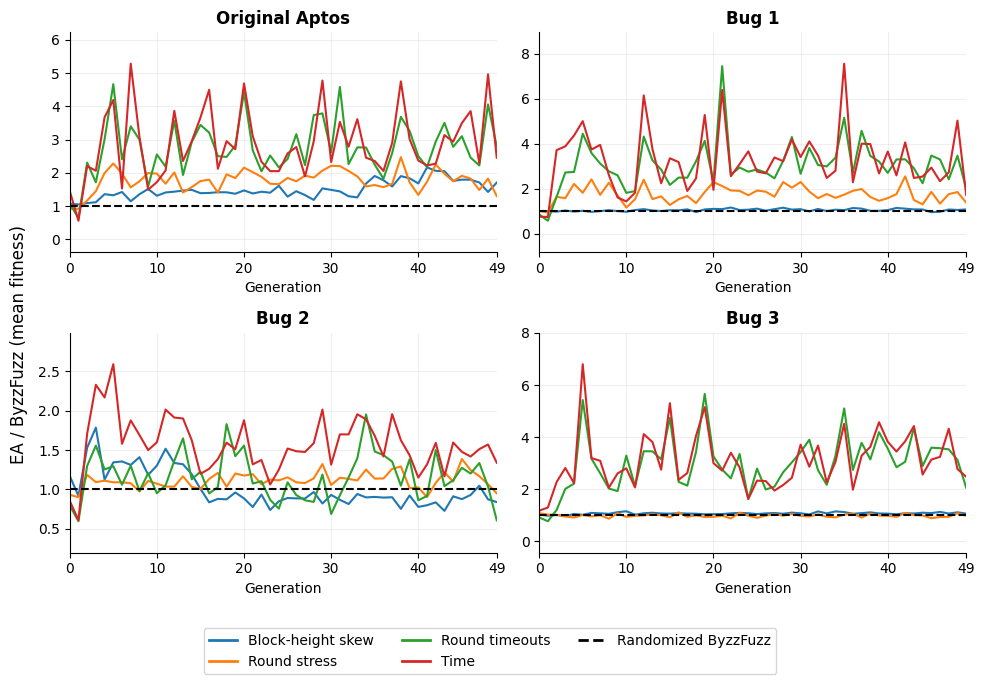

In [132]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

methods = df["method_label"].unique()
colors = dict(zip(methods, sns.color_palette(n_colors=len(methods))))

for ax, benchmark in zip(axes.flat, df["benchmark_label"].unique()):
    for method in methods:
        series = df.loc[
            (df["benchmark_label"] == benchmark)
            & (df["method_label"] == method)
        ].sort_values("generation")

        sns.lineplot(
            data=series,
            x="generation",
            y="mean_ratio",
            color=colors[method],
            estimator=None,
            errorbar=None,
            sort=True,
            linewidth=1.5,
            legend=False,
            ax=ax,
        )

    # Randomized ByzzFuzz is the denominator, so its reference is ratio = 1.
    ax.axhline(1, color="black", linestyle="--", linewidth=1.5, zorder=10)

    sns.despine(ax=ax)    
    ax.margins(y=0.2)
    ax.set_title(benchmark, fontweight="bold")
    ax.set_xlim(0, 49)
    ax.set_xticks([0, 10, 20, 30, 40, 49])
    ax.set_xlabel("Generation")
    ax.set_ylabel("")
    ax.grid(alpha=0.2)
    
fig.supylabel("EA / ByzzFuzz (mean fitness)")
handles = [
    plt.Line2D(
        [0], [0],
        color=colors[method],
        linestyle="--" if method == "Randomized ByzzFuzz" else "-",
        linewidth=2,
        label=method,
    )
    for method in df['method_label'].unique()
]
handles += [
    plt.Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=2,
        label="Randomized ByzzFuzz")
]
fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.02),
)

fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

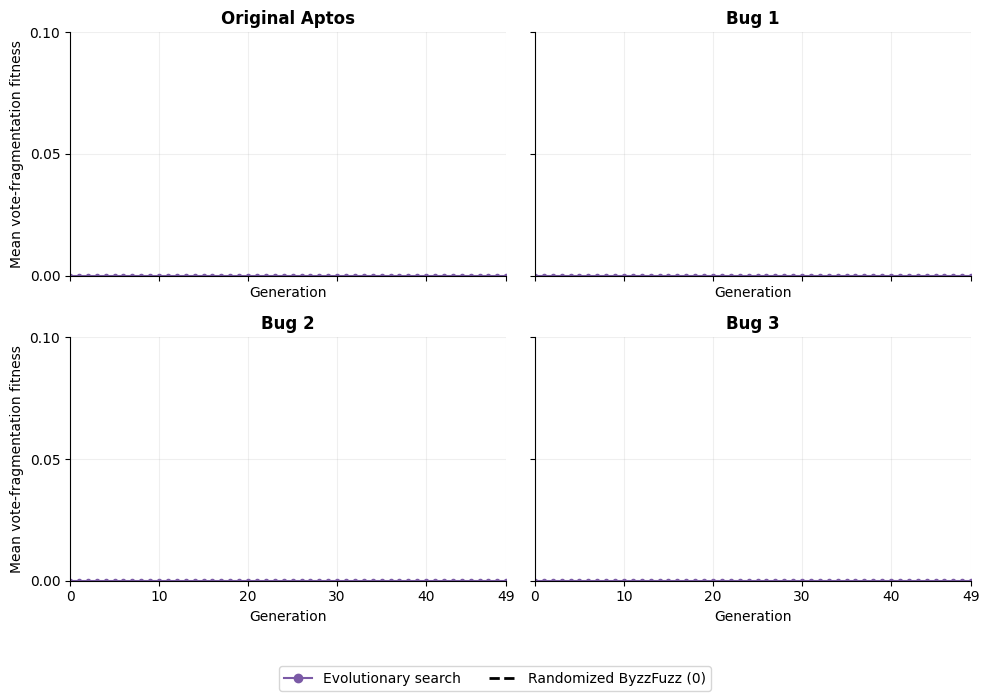

In [133]:
from matplotlib.lines import Line2D

means = pd.read_csv("./final-thesis-bug4-as-bug3/data/rq3_mean_fitness_ratio_by_generation.csv")
plot_df = means[means["fitness_metric"] == "vote_fragmentation_fitness"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)

for ax, benchmark in zip(axes.flat, plot_df["benchmark_label"].unique()):
    series = (
        plot_df[plot_df["benchmark_label"] == benchmark]
        .sort_values("generation")
    )
    
    # Draw randomized first so the EA line remains visible when both are zero.
    ax.plot(
        series["generation"], series["mean_randomized_fitness"],
        color="black", linestyle="--", linewidth=2,
    )
    ax.plot(
        series["generation"], series["mean_ea_fitness"],
        color="#7b5aa6", marker="o", markersize=3, linewidth=1.5,
    )

    ax.set_title(benchmark, fontweight="bold")
    ax.set_xlim(0, 49)
    ax.set_xticks([0, 10, 20, 30, 40, 49])
    ax.set_ylim(0, 0.1)
    ax.set_yticks([0, 0.05, 0.1])
    ax.set_xlabel("Generation")
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_ylabel("Mean vote-fragmentation fitness")
axes[1, 0].set_ylabel("Mean vote-fragmentation fitness")

handles = [
    Line2D([0], [0], color="#7b5aa6", marker="o",
           linewidth=1.5, label="Evolutionary search"),
    Line2D([0], [0], color="black", linestyle="--",
           linewidth=2, label="Randomized ByzzFuzz (0)"),
]
fig.legend(handles=handles, loc="lower center", ncol=2)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


In [134]:
df = pd.read_csv("./final-thesis-bug4-as-bug3/data/rq3_bug2_vote_fragmentation_r10_mean_ratio_by_generation.csv")
df

,benchmark,benchmark_label,fitness_metric,configured_r,generation,x_axis_basis,mean_ea_fitness,mean_randomized_fitness,paired_seed_count,ea_execution_count,randomized_execution_count,mean_ratio
0,bug2,Bug 2,vote_fragmentation_fitness,10,0,EA generation / corresponding randomized 20-ex...,0.00,0.09,5,100,100,0.000
1,bug2,Bug 2,vote_fragmentation_fitness,10,1,EA generation / corresponding randomized 20-ex...,0.00,0.05,5,100,100,0.000
2,bug2,Bug 2,vote_fragmentation_fitness,10,2,EA generation / corresponding randomized 20-ex...,0.00,0.08,5,100,100,0.000
3,bug2,Bug 2,vote_fragmentation_fitness,10,3,EA generation / corresponding randomized 20-ex...,0.01,0.08,5,100,100,0.125
4,bug2,Bug 2,vote_fragmentation_fitness,10,4,EA generation / corresponding randomized 20-ex...,0.00,0.08,5,100,100,0.000
5,bug2,Bug 2,vote_fragmentation_fitness,10,5,EA generation / corresponding randomized 20-ex...,0.00,0.07,5,100,100,0.000
6,bug2,Bug 2,vote_fragmentation_fitness,10,6,EA generation / corresponding randomized 20-ex...,0.00,0.08,5,100,100,0.000
7,bug2,Bug 2,vote_fragmentation_fitness,10,7,EA generation / corresponding randomized 20-ex...,0.00,0.14,5,100,100,0.000


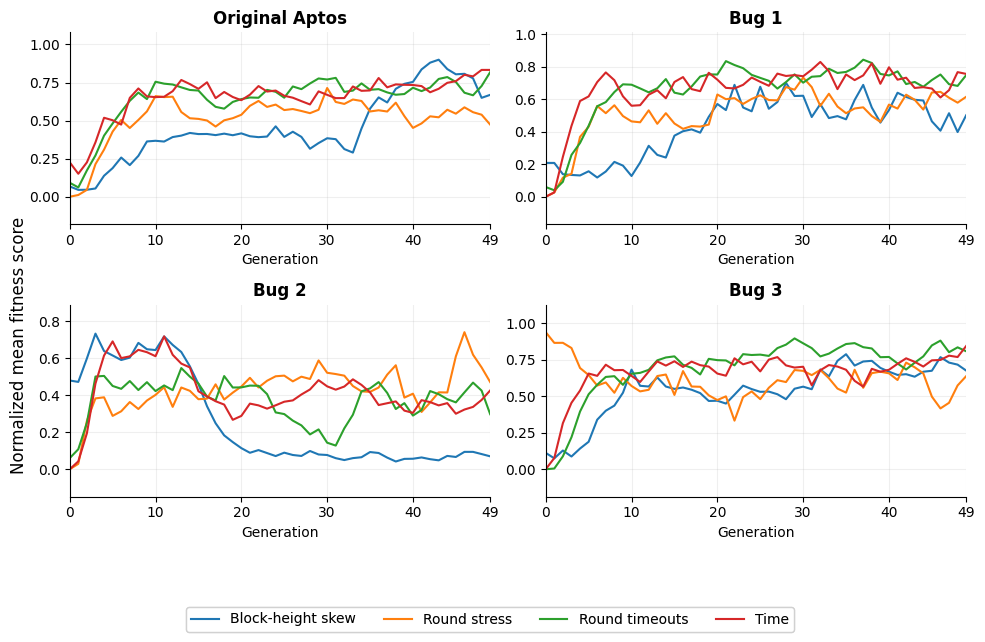

In [135]:
df = pd.read_csv(
    "./final-thesis-bug4-as-bug3/data/rq3_mean_fitness_ratio_by_generation.csv"
)
df = df[df["ratio_defined"]]

benchmarks = df["benchmark_label"].unique()
methods = df["method_label"].unique()
colors = dict(zip(methods, sns.color_palette(n_colors=len(methods))))

fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, benchmark in zip(axes.flat, benchmarks):
    for method in methods:
        series = df.loc[
            (df["benchmark_label"] == benchmark)
            & (df["method_label"] == method)
        ].sort_values("generation")
        series["mean_ea_fitness"] = (series["mean_ea_fitness"] - series["mean_ea_fitness"].min()) / (series["mean_ea_fitness"].max() - series["mean_ea_fitness"].min())
        series["ea_ewma"] = series["mean_ea_fitness"].ewm(
            span=5, adjust=False
        ).mean()
        
        sns.lineplot(
            data=series,
            x="generation",
            y="ea_ewma",
            color=colors[method],
            estimator=None,
            errorbar=None,
            sort=True,
            linewidth=1.5,
            legend=False,
            ax=ax,
        )

    sns.despine(ax=ax)
    ax.margins(y=0.2)
    ax.set_title(benchmark, fontweight="bold")
    ax.set_xlim(0, 49)
    ax.set_xticks([0, 10, 20, 30, 40, 49])
    ax.set_xlabel("Generation")
    ax.set_ylabel("")
    ax.grid(alpha=0.2)

fig.supylabel("Normalized mean fitness score")

fitness_handles = [
    Line2D([0], [0], color=colors[method], linewidth=1.5, label=method)
    for method in methods
]

fitness_legend = fig.legend(
    handles=fitness_handles,
    loc="lower center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.08)
)
fig.add_artist(fitness_legend)

fig.tight_layout(rect=(0, 0.20, 1, 1))
plt.show()

In [136]:
df[(df["method_label"] == "Vote fragmentation") & (df["ratio_defined"] == False)]

,benchmark,benchmark_label,method,method_label,fitness_metric,generation,x_index,x_axis_basis,mean_ea_fitness,mean_randomized_fitness,mean_ratio,mean_fitness_difference,paired_seed_count,ea_valid_executions,randomized_valid_executions,ratio_defined


*RQ3* Fitness signal: How well do these 5 fitnesses work? Can they distinguish non-violating execs from violating execs?

In [141]:
df = pd.read_csv("./final-thesis-bug4-as-bug3/data/fitness_scores_all_executions.csv")
#df = df[df["configuration"].isin(FINAL_CONFIGS)]

df.fitness.unique()
df.is_violation.unique()

array([ 0.,  1., nan])

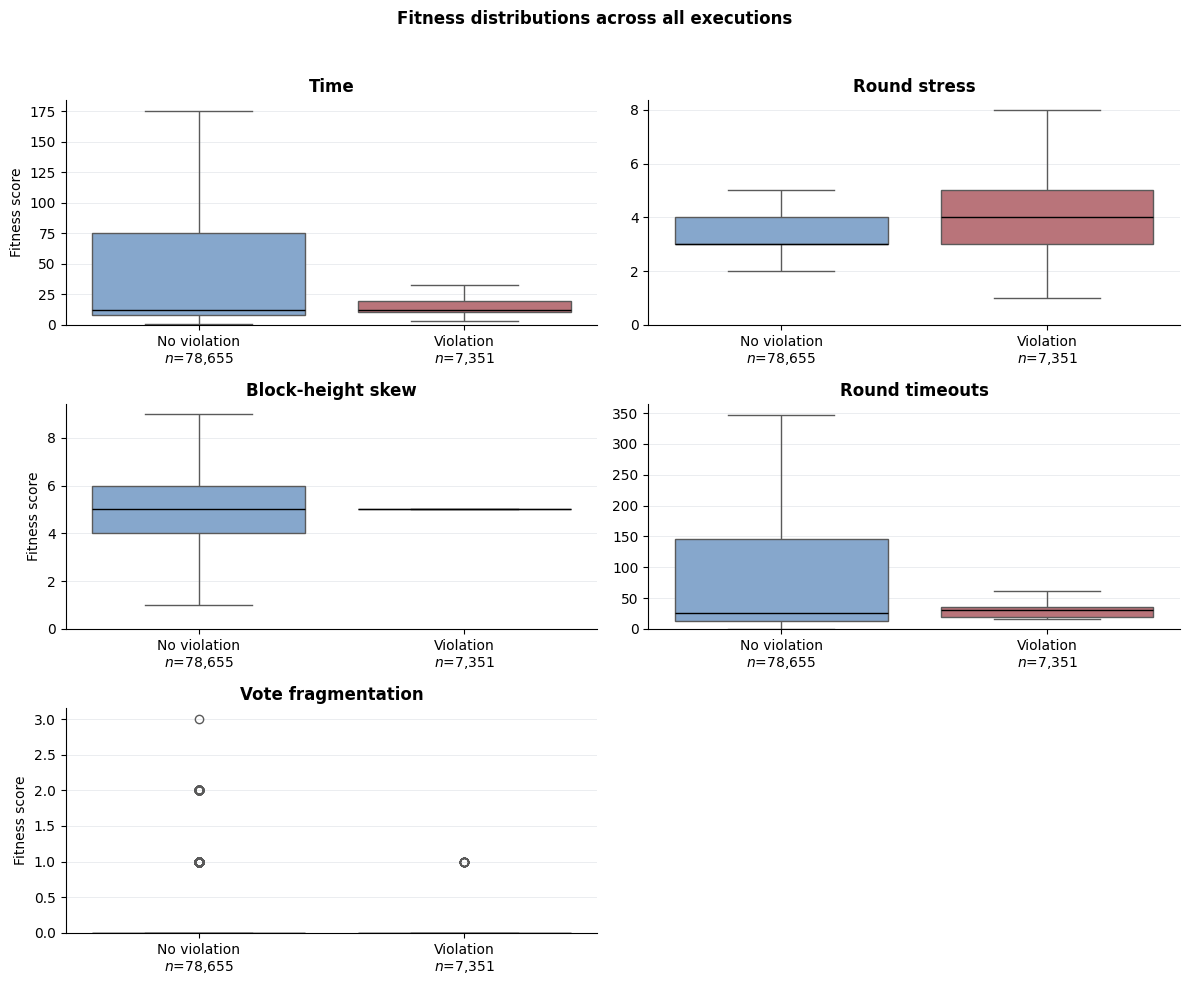

In [144]:
from matplotlib.patches import Patch

plot_df = df.loc[df["is_analyzable"]].copy()

scores = {
    "time_fitness": "Time",
    "round_stress_fitness": "Round stress",
    "block_height_skew_fitness": "Block-height skew",
    "round_timeout_count_fitness": "Round timeouts",
    "vote_fragmentation_fitness": "Vote fragmentation",
}
order = ["No violation", "Confirmed violation"]
palette = {
    "No violation": "#7AA6D8",
    "Confirmed violation": "#C56870",
}

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, (ax, (score, title)) in enumerate(zip(axes.flat, scores.items())):
    sns.boxplot(
        data=plot_df,
        x="violation_status",
        y=score,
        hue="violation_status",
        order=order,
        hue_order=order,
        palette=palette,
        dodge=False,
        showfliers=True if title == "Vote fragmentation" else False,
        medianprops={"color": "black", "linewidth": 1},
        ax=ax,
    )

    if ax.get_legend():
        ax.get_legend().remove()

    counts = plot_df["violation_status"].value_counts()
    ax.set_xticks(
        np.arange(len(order)),
        [
            f"No violation\n$n$={counts[order[0]]:,}",
            f"Violation\n$n$={counts[order[1]]:,}",
        ],
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Fitness score" if i % 2 == 0 else "")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#D9DDE2", linewidth=0.55, alpha=0.65)
    ax.set_axisbelow(True)
    ax.set_ylim(bottom=0)

axes.flat[5].axis("off")


fig.suptitle("Fitness distributions across all executions", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

In [139]:
plot_df[plot_df["vote_fragmentation_fitness"] > 0]

,benchmark,benchmark_label,method,strategy,fitness,seed,campaign,configuration,configured_c,configured_d,...,is_analyzable,is_violation,violation_status,violation_type,confirmed_violation,time_fitness,round_stress_fitness,block_height_skew_fitness,round_timeout_count_fitness,vote_fragmentation_fitness
72011,bug2,Bug 2,randomized,byzzfuzz,vote_fragmentation_fitness,42,supp_node0_window_bug2_byzzfuzz_vote_fragmenta...,supplementary_randomized_r10,2,1,...,True,0.0,No violation,No violation,False,104.383129,4.0,5.0,128.0,1.0
72014,bug2,Bug 2,randomized,byzzfuzz,vote_fragmentation_fitness,42,supp_node0_window_bug2_byzzfuzz_vote_fragmenta...,supplementary_randomized_r10,2,1,...,True,0.0,No violation,No violation,False,10.148474,4.0,5.0,24.0,1.0
72018,bug2,Bug 2,randomized,byzzfuzz,vote_fragmentation_fitness,42,supp_node0_window_bug2_byzzfuzz_vote_fragmenta...,supplementary_randomized_r10,2,1,...,True,0.0,No violation,No violation,False,9.130651,3.0,5.0,24.0,1.0
72032,bug2,Bug 2,randomized,byzzfuzz,vote_fragmentation_fitness,42,supp_node0_window_bug2_byzzfuzz_vote_fragmenta...,supplementary_randomized_r10,2,1,...,True,0.0,No violation,No violation,False,64.846491,6.0,7.0,99.0,1.0
72048,bug2,Bug 2,randomized,byzzfuzz,vote_fragmentation_fitness,42,supp_node0_window_bug2_byzzfuzz_vote_fragmenta...,supplementary_randomized_r10,2,1,...,True,0.0,No violation,No violation,False,11.156393,4.0,5.0,16.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80762,bug2,Bug 2,vote_fragmentation_fitness,evo_aptos,vote_fragmentation_fitness,271828,supp_node14_window_bug2_evo_aptos_vote_fragmen...,supplementary_evo_r12,2,1,...,True,0.0,No violation,No violation,False,8.125930,5.0,6.0,14.0,1.0
80765,bug2,Bug 2,vote_fragmentation_fitness,evo_aptos,vote_fragmentation_fitness,271828,supp_node14_window_bug2_evo_aptos_vote_fragmen...,supplementary_evo_r12,2,1,...,True,1.0,Confirmed violation,Agreement,True,17.247128,5.0,6.0,39.0,1.0
80769,bug2,Bug 2,vote_fragmentation_fitness,evo_aptos,vote_fragmentation_fitness,271828,supp_node14_window_bug2_evo_aptos_vote_fragmen...,supplementary_evo_r12,2,1,...,True,1.0,Confirmed violation,Agreement,True,19.239872,4.0,4.0,41.0,1.0
80772,bug2,Bug 2,vote_fragmentation_fitness,evo_aptos,vote_fragmentation_fitness,271828,supp_node14_window_bug2_evo_aptos_vote_fragmen...,supplementary_evo_r12,2,1,...,True,1.0,Confirmed violation,Agreement,True,19.276583,3.0,5.0,51.0,1.0


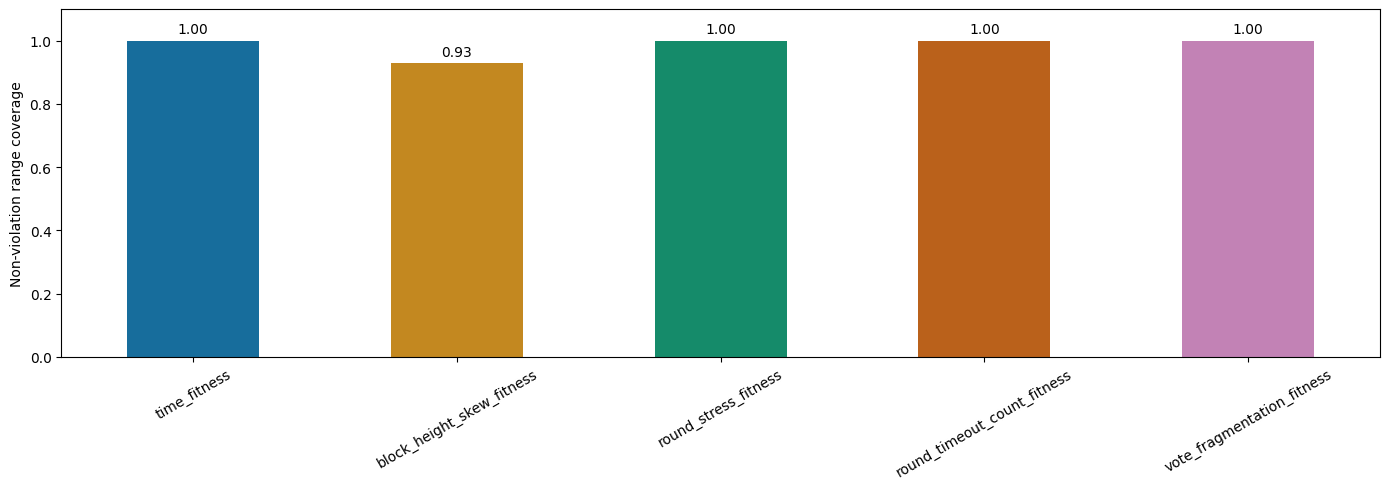

In [145]:
range = {}
non_violations = plot_df[plot_df["is_violation"] == 0.0]

for fitness in plot_df["fitness"].unique():
    D = plot_df[fitness].max() - plot_df[fitness].min()
    d = non_violations[fitness].max() - non_violations[fitness].min()
    range[fitness] = d / D if D != 0 else np.nan
    

range_df = pd.DataFrame({
    "fitness": list(range.keys()),
    "coverage": list(range.values()),
})

palette = dict(zip(
    range_df["fitness"],
    sns.color_palette("colorblind", n_colors=len(range_df)),
))

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=range_df,
                x="fitness",
                y="coverage",
                hue="fitness",
                palette=palette,
                dodge=False,
                legend=False,
                width=0.5,
                ax=ax
            )

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_ylim(0, 1.1)  # room for labels above bars

ax.set_ylabel("Non-violation range coverage")
ax.set_xlabel("")
ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()


In [ ]:
range_df

,fitness,coverage
0,time_fitness,1.000000
1,block_height_skew_fitness,0.928571
2,round_stress_fitness,1.000000
3,round_timeout_count_fitness,1.000000
4,vote_fragmentation_fitness,1.000000
